# PSIONIC Tutorial part 2

**Date:** 2026-07-30

**Author:** Jiahui Hou (jih325@pitt.edu)

**Data required:** scATAC-seq + scRNA-seq

The PSIONIC tutorial has two parts. In the first part, I demonstrate the code for tuning the PSIONIC model using cross-validation and selecting the best-performing model hyperparameters. In the second part, I demonstrate how to run the model on the full dataset using those best hyperparameters, then interpret the model output and perform differential TF activity analysis.

## Main steps of part 2

1. **Step 1.** Run PSIONIC on full dataset using best hyperparameters
2. **Step 2.** Examine sample weight matrix (S)
3. **Step 3.** Examine latent regulatory program (L)
4. **Step 4.** Differential TF activity analysis

## Step 1. Run PSIONIC on the full dataset using the best hyperparameters

For this part, we use the same cell-type x sample scRNA-seq pseudobulk `Y` and TF-target gene matrix `D` created in the first part of the tutorial.

In [1]:
import os
import numpy as np
import pandas as pd
import time
from itertools import product, combinations
from scipy.stats import zscore, spearmanr, rankdata
import matplotlib.pyplot as plt
import anndata as ad
import scanpy as sc
import seaborn as sns
import pickle
from joblib import Parallel, delayed
from tqdm.auto import tqdm
import gc
import psutil
import sys
import gzip

# PSIONIC code
from psionic import GO_MTL, normalize_column

In [2]:
# =====================================================
# 1. Load data
# =====================================================

#--> loading Y
Y_filtered = ad.read_h5ad("./data/toy_Y.h5ad")

# normalize and transformation
sc.pp.normalize_total(Y_filtered, target_sum=1e4)
sc.pp.log1p(Y_filtered)

Y = Y_filtered.X
if hasattr(Y, "toarray"):
    Y = Y.toarray()
Y = Y.T  # gene × task

print(f"Y shape: {Y.shape}")

n_genes, n_tasks = Y.shape


Y shape: (803, 1348)


In [3]:
#--> loading D
#load the same D for tasks of the same cell type
TF_DIR = "./SCRIP_out"
D_dict = {}
tf_names = None

# Get pseudobulk IDs in order
# Pseudobulk IDs are in the format of {subject}_{celltype}_{replicate_id}
pb_ids_ordered = Y_filtered.obs_names.tolist()

# Load each cell-type D once
D_sub_cache = {}  # cache of D_sub per cell type
cell_types = sorted({pb_id.split("_")[1] for pb_id in pb_ids_ordered})

for ct in cell_types:
    D_file = os.path.join(TF_DIR, f"{ct}_TFxGene.h5ad")
    if not os.path.exists(D_file):
        raise FileNotFoundError(f"TF file not found for cell type {ct}")

    # Load TF×gene AnnData
    D_adata = ad.read_h5ad(D_file)
    
    common_genes = Y_filtered.var_names.intersection(D_adata.var_names)
    D_sub = D_adata[:,common_genes].copy()
    print(f"D shape: {D_sub.shape}")
    
    D_sub_cache[ct] = D_sub  # store for later reuse

    # Save TF names once
    if tf_names is None:
        tf_names = D_adata.obs_names.tolist()

# Assign to D_dict in the same order as Y_filtered.obs_names
for pb_id in pb_ids_ordered:
    ct = pb_id.split("_")[1]
    X_mat = D_sub_cache[ct].X.T
    if hasattr(X_mat, "toarray"):
        X_mat = X_mat.toarray()
    D_dict[pb_id] = X_mat # gene × TF

D shape: (50, 803)
D shape: (50, 803)


In [4]:
# =====================================================
# 2. Preprocessing (per task)
# =====================================================
x_all, y_all = [], []

for t, ids in enumerate(pb_ids_ordered):
    x = zscore(np.log10(D_dict[ids] + 1), axis=0)   # gene × TF
    y = normalize_column(Y[:, t:t+1])              # gene × 1

    x_all.append(x)
    y_all.append(y)


del Y_filtered,  Y, D_adata, D_sub, D_sub_cache, X_mat, D_dict
gc.collect()


130

Here we run the model on the full dataset without splitting them into folds. Below, we can set up the best-performing hyperparameter values.

In [5]:
# =====================================================
# 3. Hyperparameters setup
# =====================================================
O = "R"
Maxsteps = 20
current_k = 3
current_lambda = 1e-2
current_mu = 1

The `run_full_model` function runs the PSIONIC model on the full input data and outputs the latent regulatory program matrix `L` (TFs × latent programs `k`) and the sample weight matrix `S` (latent programs `k` × tasks), which can be used to compute TF activity (`L × S`).

In [6]:
# =====================================================
# 4. Define Full Training Function (No Folds)
# =====================================================

def run_full_model(k, lambda_, mu, n_tasks, Maxsteps, O, task_names, tf_names,
                   output_dir="results", file_prefix="20260325"):
    global x_all, y_all
    
    # ---- Use ALL genes (Full Dataset) ----
    x_train = x_all
    y_train = y_all

    print(f"--- Training Full Model: k={k}, lambda={lambda_}, mu={mu} ---")
    
    # ---- Train GO_MTL ----
    # This returns L (Features x k) and S (k x Tasks)
    L, S, _ = GO_MTL(x_train, y_train, k=k, Maxsteps=Maxsteps, lambda_=lambda_, mu=mu, O=O)

    # ---- Evaluation (Training Correlation) ----
    What = L @ S
    y_true_mat = np.hstack(y_train)
    y_pred_mat = np.zeros_like(y_true_mat)
    for t in range(n_tasks):
        y_pred_mat[:, t] = x_train[t] @ What[:, t]

    # Spearman calculation using rank-diff logic
    y_true_ranked = rankdata(y_true_mat, axis=0)
    y_pred_ranked = rankdata(y_pred_mat, axis=0)
    y_true_diff = y_true_ranked - np.mean(y_true_ranked, axis=0)
    y_pred_diff = y_pred_ranked - np.mean(y_pred_ranked, axis=0)
    num = np.sum(y_true_diff * y_pred_diff, axis=0)
    den = np.sqrt(np.sum(y_true_diff**2, axis=0) * np.sum(y_pred_diff**2, axis=0))
    task_corrs = np.divide(num, den, out=np.zeros_like(num), where=den!=0)
    
    # ---- Save L and S (Final Result) ----
    if output_dir is None:
        output_dir = "."
    os.makedirs(output_dir, exist_ok=True)
    
    ls_filename = f"{file_prefix}_FULL_LS_k{k}_L{lambda_}_M{mu}.pkl.gz"
    ls_filepath = os.path.join(output_dir, ls_filename)
    
    with gzip.open(ls_filepath, "wb") as f:
        pickle.dump(
            {
                "L": L,
                "S": S,
                "k": k,
                "lambda": lambda_,
                "mu": mu,
                "task_names": task_names,
                "tf_names": tf_names,
                "train_correlations": task_corrs
            },
            f,
            protocol=pickle.HIGHEST_PROTOCOL
        )
    
    score = np.nanmean(task_corrs)
    print(f"Full Model Training Finished. Mean Spearman: {score:.4f}")
    print(f"File saved to: {ls_filepath}")
    return score

In [7]:
# =====================================================
# 5. Execution
# =====================================================

start_time = time.time()

# Run the full training
score_final = run_full_model(
    current_k,
    current_lambda,
    current_mu,
    n_tasks,
    Maxsteps,
    O,
    pb_ids_ordered,
    tf_names,
    output_dir="./PSIONIC_out",
    file_prefix="20260726_example_run"
)

runtime = time.time() - start_time
print(f"Total Runtime: {runtime/3600:.2f} hours")

--- Training Full Model: k=3, lambda=0.01, mu=1 ---
Full Model Training Finished. Mean Spearman: 0.3826
File saved to: ./PSIONIC_out/20260726_example_run_FULL_LS_k3_L0.01_M1.pkl.gz
Total Runtime: 0.00 hours


## Step 2. Examine the sample weight matrix (`S`)

For each latent regulatory program `k`, we can compute the mean of the sample weight matrix (`S`) grouped by cell type. This lets us see whether a given regulatory program captures cell-type-specific TF-gene regulatory relationships.

In [8]:
# 1. Load the data
folder = "./PSIONIC_out"
filename = "20260726_example_run_FULL_LS_k3_L0.01_M1.pkl.gz"
filepath = os.path.join(folder, filename)

with gzip.open(filepath, "rb") as f:
    data = pickle.load(f)

task_names = data['task_names'] 
k = data['k']  

S = data['S']                 
S.shape

(3, 1348)

In [9]:
# 2. extract cell types
cell_types = [name.split('_')[1] for name in task_names] 

# 3. Create DataFrame and Transpose
# We transpose (.T) so rows = tasks and columns = programs
df = pd.DataFrame(S, index=[f"Program {i+1}" for i in range(k)]).T
df['CellType'] = cell_types
df.head()

,Program 1,Program 2,Program 3,CellType
0,-0.005164,0.002497,0.0,Exc
1,-0.005171,0.002645,0.0,Exc
2,-0.005196,0.002433,0.0,Exc
3,-0.005070,0.002408,0.0,Exc
4,-0.005242,0.002644,0.0,Exc


In [10]:
# 4. Melt to Long Format
# This creates columns: 'CellType', 'Program', and 'Weight'
df_melted = df.melt(id_vars='CellType', var_name='Program', value_name='Weight')
df_melted.head()

,CellType,Program,Weight
0,Exc,Program 1,-0.005164
1,Exc,Program 1,-0.005171
2,Exc,Program 1,-0.005196
3,Exc,Program 1,-0.005070
4,Exc,Program 1,-0.005242


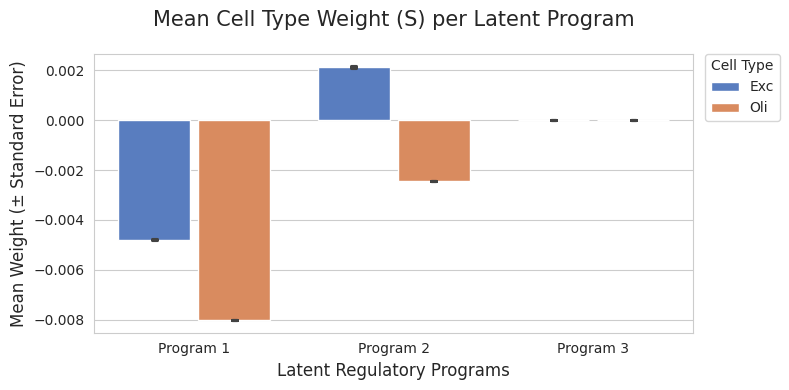

In [11]:
# 5. Plotting
plt.figure(figsize=(8, 4))
sns.set_style("whitegrid")

# errorbar='se' calculates the Standard Error automatically
ax = sns.barplot(
    data=df_melted,
    x='Program',
    y='Weight',
    hue='CellType',
    gap=0.1,         # Adds a small space between bars within a group
    capsize=.05,
    errorbar='se',
    palette='muted'
)

# Refine labels and layout
plt.title('Mean Cell Type Weight (S) per Latent Program', fontsize=15, pad=20)
plt.ylabel('Mean Weight (± Standard Error)', fontsize=12)
plt.xlabel('Latent Regulatory Programs', fontsize=12)

# Move legend outside the plot area
plt.legend(title='Cell Type', bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

plt.tight_layout()
plt.show()

From this figure, we can see that latent program 1 is shared by excitatory neurons and oligodendrocytes, while latent program 2 captures the TF regulatory axis that separates the two cell types.

## Step 3. Examine the latent regulatory programs (`L`)

Now we can take a closer look at individual latent regulatory program. For a given program (i.e., each column of the `L` matrix), we can rank the TFs by the magnitude of their coefficients. Taking latent program 2 as an example, we would expect neuronal-cell-related TFs to have the highest positive loadings and glial-cell-related TFs to have the most negative loadings.

In [12]:
# function to do a dot plot
def plot_single_L_program(data, k_idx, program_label=None, 
                          figsize=(8, 6), top_n=10, save_path=None):
 
    # ---- Load data ----
    L = data["L"]
    tf_names = data["tf_names"]
    
    # Extract coefficients for the single chosen program
    coeffs = L[:, k_idx]

    # Sort TFs by coefficient to create the "S-curve" distribution
    sorted_idx = np.argsort(coeffs)
    sorted_coeffs = coeffs[sorted_idx]
    sorted_tf_names = [tf_names[j] for j in sorted_idx]
    ranks = np.arange(1, len(sorted_coeffs) + 1)

    # ---- Plotting ----
    fig, ax = plt.subplots(figsize=figsize)

    # Background: Scatter all genes
    ax.scatter(ranks, sorted_coeffs, color="lightgrey", s=15, alpha=0.4, rasterized=True)

    # Identify indices for labels (Top Positive and Top Negative)
    pos_indices = np.arange(len(sorted_tf_names) - top_n, len(sorted_tf_names))
    neg_indices = np.arange(top_n)
    
    # Calculate a small X-offset to move text away from the dot
    x_offset = len(ranks) * 0.02 

    # Highlight and Label important regulators
    for idx in np.concatenate([neg_indices, pos_indices]):
        val = sorted_coeffs[idx]
        name = sorted_tf_names[idx]
        rank = ranks[idx]
        
        # Color coding: Red for (+), Blue for (-)
        color = "#e31a1c" if val > 0 else "#1f78b4"
        ax.scatter(rank, val, color=color, s=50, zorder=3, edgecolors='white', linewidth=0.5)
        
        # Logic for alignment and overlap reduction:
        # Positive (top right): Label on the left (ha="right")
        # Negative (bottom left): Label on the right (ha="left")
        if val > 0:
            alignment = "right"
            x_pos = rank - x_offset
        else:
            alignment = "left"
            x_pos = rank + x_offset

        ax.text(x_pos, val, name, 
                fontsize=10, 
                ha=alignment, 
                va="center", 
                fontweight='normal', # Removed bold
                zorder=4)

    # ---- Formatting ----
    title = program_label if program_label else f"Latent regulatory program {k_idx + 1}"
    ax.set_title(title, fontsize=16, fontweight='bold', pad=20)
    
    ax.axhline(0, color="black", linestyle="--", linewidth=1, alpha=0.6)
    ax.set_xlabel("Transcription factor rank", fontsize=12)
    ax.set_ylabel("Latent regulatory program weight", fontsize=12)
    
    # Remove unnecessary chart junk
    ax.grid(axis='y', linestyle=':', alpha=0.4)

    plt.tight_layout()

    if save_path:
        fig.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"Program {k_idx+1} plot saved to: {save_path}")

    return fig, ax

(<Figure size 800x600 with 1 Axes>,
 <Axes: title={'center': 'Latent regulatory program 2'}, xlabel='Transcription factor rank', ylabel='Latent regulatory program weight'>)

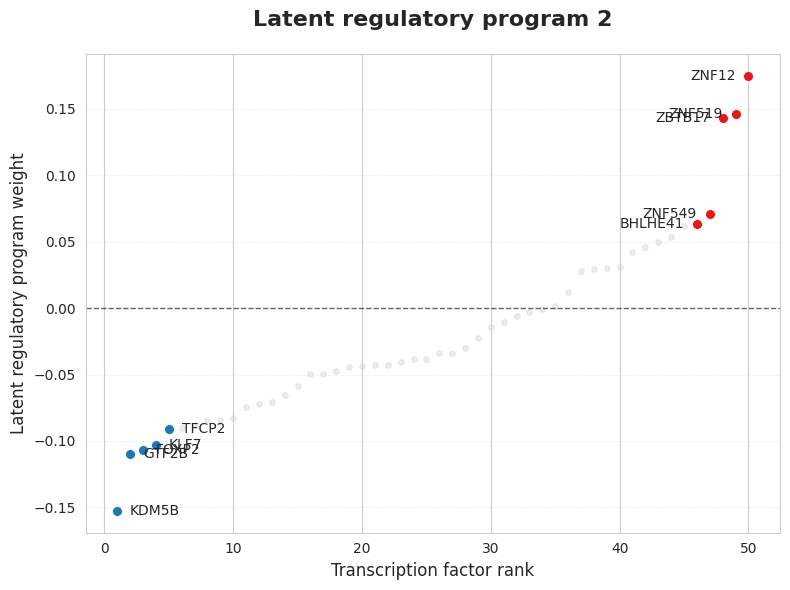

In [13]:
plot_single_L_program(data, k_idx=1,  figsize=(8, 6), top_n=5, save_path=None)

## Step 4. Differential TF activity analysis

We can also compute cell-type-specific TF activities for each sample using `L × S`. Within each cell type, we can then compare TF activities between groups. Here, I provide the Alzheimer's disease group information `"metadata.csv` for each sample, allowing us to identify AD-associated TFs in each cell type.

In [14]:
# 1. calculate TF activity
L, S = data['L'], data['S']
W = L @ S

# tasknames, tf_names
tasks = data['task_names']
TFs = data['tf_names']

df_w = pd.DataFrame(W, index=TFs, columns=tasks).T
df_w.shape

(1348, 50)

In [15]:
df_w.head()

,ATF6,BHLHE40,BHLHE41,CREBL2,DPF1,ELK4,ETS2,ETV6,FBXL19,FOXK1,...,ZNF235,ZNF266,ZNF273,ZNF324,ZNF398,ZNF432,ZNF519,ZNF549,ZNF75A,ZNF790
ROSMAP-10859_Exc_rep1,0.000667,-0.000573,0.000675,0.000013,-0.000480,-0.000358,-0.000225,-0.000436,0.000546,0.000755,...,0.000674,-0.000072,0.001149,-0.000394,0.000697,0.001129,0.001707,0.000105,-0.000844,-0.000283
ROSMAP-10859_Exc_rep2,0.000675,-0.000586,0.000685,0.000017,-0.000487,-0.000363,-0.000231,-0.000433,0.000549,0.000743,...,0.000668,-0.000078,0.001155,-0.000407,0.000703,0.001139,0.001730,0.000116,-0.000847,-0.000293
ROSMAP-10859_Exc_rep3,0.000668,-0.000570,0.000675,0.000010,-0.000480,-0.000357,-0.000223,-0.000441,0.000549,0.000767,...,0.000682,-0.000069,0.001153,-0.000390,0.000699,0.001131,0.001706,0.000100,-0.000848,-0.000280
ROSMAP-10859_Exc_rep4,0.000653,-0.000559,0.000660,0.000011,-0.000470,-0.000350,-0.000219,-0.000429,0.000536,0.000746,...,0.000664,-0.000068,0.001127,-0.000384,0.000683,0.001106,0.001669,0.000100,-0.000828,-0.000275
ROSMAP-12078_Exc_rep1,0.000682,-0.000591,0.000692,0.000016,-0.000492,-0.000367,-0.000233,-0.000439,0.000556,0.000757,...,0.000678,-0.000077,0.001169,-0.000409,0.000711,0.001153,0.001749,0.000115,-0.000858,-0.000295


In [16]:
# 2. get disease metadata
import pandas as pd
metadata = pd.read_csv("./data/metadata.csv")
metadata = metadata.set_index("Unnamed: 0")
metadata.head()

,Subject,CellType,Replicate,Pathology,age_death,msex
Unnamed: 0,,,,,,
ROSMAP-10859_Exc_rep1,ROSMAP-10859,Exc,rep1,lateAD,80-85,1
ROSMAP-10859_Exc_rep2,ROSMAP-10859,Exc,rep2,lateAD,80-85,1
ROSMAP-10859_Exc_rep3,ROSMAP-10859,Exc,rep3,lateAD,80-85,1
ROSMAP-10859_Exc_rep4,ROSMAP-10859,Exc,rep4,lateAD,80-85,1
ROSMAP-12078_Exc_rep1,ROSMAP-12078,Exc,rep1,earlyAD,85-90,1


In [17]:
df_final = pd.concat([metadata, df_w], axis=1)
df_final.head()

,Subject,CellType,Replicate,Pathology,age_death,msex,ATF6,BHLHE40,BHLHE41,CREBL2,...,ZNF235,ZNF266,ZNF273,ZNF324,ZNF398,ZNF432,ZNF519,ZNF549,ZNF75A,ZNF790
ROSMAP-10859_Exc_rep1,ROSMAP-10859,Exc,rep1,lateAD,80-85,1,0.000667,-0.000573,0.000675,0.000013,...,0.000674,-0.000072,0.001149,-0.000394,0.000697,0.001129,0.001707,0.000105,-0.000844,-0.000283
ROSMAP-10859_Exc_rep2,ROSMAP-10859,Exc,rep2,lateAD,80-85,1,0.000675,-0.000586,0.000685,0.000017,...,0.000668,-0.000078,0.001155,-0.000407,0.000703,0.001139,0.001730,0.000116,-0.000847,-0.000293
ROSMAP-10859_Exc_rep3,ROSMAP-10859,Exc,rep3,lateAD,80-85,1,0.000668,-0.000570,0.000675,0.000010,...,0.000682,-0.000069,0.001153,-0.000390,0.000699,0.001131,0.001706,0.000100,-0.000848,-0.000280
ROSMAP-10859_Exc_rep4,ROSMAP-10859,Exc,rep4,lateAD,80-85,1,0.000653,-0.000559,0.000660,0.000011,...,0.000664,-0.000068,0.001127,-0.000384,0.000683,0.001106,0.001669,0.000100,-0.000828,-0.000275
ROSMAP-12078_Exc_rep1,ROSMAP-12078,Exc,rep1,earlyAD,85-90,1,0.000682,-0.000591,0.000692,0.000016,...,0.000678,-0.000077,0.001169,-0.000409,0.000711,0.001153,0.001749,0.000115,-0.000858,-0.000295


Below is the function to identify differential TFs using a linear regression model. We use age and sex as covariates and compare between nonAD and lateAD.

In [18]:
#linear regression with covariates
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf


def run_regression(df, cell_type, base_stage='nonAD', target_stage='lateAD',  out_csv="tf_activity_comparison_lm.csv"):
    # 1. Filter for cell type and the two stages
    subset = df[df['CellType'] == cell_type].copy()
    subset = subset[subset['Pathology'].isin([base_stage, target_stage])].copy()
    
    # 2. 
    # We ensure age and sex are strings/categories so the model creates dummy variables
    subset['age_death'] = subset['age_death'].astype(str)
    subset['msex'] = subset['msex'].astype(str)
    
    # 3. Setup the AD Stage as a binary indicator
    subset['is_target'] = (subset['Pathology'] == target_stage).astype(int)
    

    results = []
    
    for tf in TFs:
        
        try:
            model_data = subset[['is_target', 'age_death', 'msex', tf]].copy()
            model_data.columns = ['is_target', 'age', 'sex', 'TF_activity']

            # 2. Define the OLS model
            model = smf.ols("TF_activity ~ is_target + C(age) + C(sex)", data=model_data)
            result = model.fit()

            # 3. Extract statistics for 'is_target'
            results.append({
                "cell_type": cell_type,
                'TF': tf,
                'coef': result.params['is_target'],
                'pval': result.pvalues['is_target']
            })

        except Exception as e:
            print(f"Skipping {tf} due to error: {e}")
            results.append({
                    "cell_type": cell_type,
                    "TF": tf,
                    "coef": np.nan,
                    "pval": np.nan,
                    "error": str(e)
                })
            continue
            
    df_results = pd.DataFrame(results)
    
    # 4. FDR Correction
    if not df_results.empty:
        mask = df_results["pval"].notna()
        df_results.loc[mask, "pval_adj"] = multipletests(df_results.loc[mask, "pval"], method="fdr_bh")[1]
    
    # Save
    if out_csv:
        df_results.to_csv(out_csv, index=False)
    
    return df_results


In [19]:
#nonAD vs lateAD
stats = []
celltypes = df_final["CellType"].unique()

for celltype in celltypes:
    df_results = run_regression(df_final, celltype,
                                   base_stage='nonAD', target_stage='lateAD',
                                   out_csv=None)
    stats.append(df_results)
    
df_stats = pd.concat(stats, ignore_index=True)

top_tfs = (
    df_stats.dropna(subset=['pval_adj']) # Remove any failed models
    .sort_values(by=['cell_type', 'pval', "coef"], ascending=[True, True, False]) # Alphabetical cell type, Smallest p-val, Largest coefficient
    .groupby('cell_type')
    .head(10)
)
top_tfs

,cell_type,TF,coef,pval,pval_adj
30,Exc,STAT5B,7.602429e-05,1.535840e-25,2.394178e-24
16,Exc,JDP2,6.577661e-05,1.862278e-25,2.394178e-24
9,Exc,FOXK1,7.252961e-05,1.877255e-25,2.394178e-24
21,Exc,MAZ,6.684597e-05,2.246589e-25,2.394178e-24
25,Exc,MZF1,4.432942e-05,2.394178e-25,2.394178e-24
23,Exc,MEIS2,2.306690e-05,3.534095e-25,2.945079e-24
32,Exc,TCF4,2.896593e-05,6.043552e-25,4.316823e-24
18,Exc,KDM5B,1.068923e-04,1.068910e-23,6.455799e-23
40,Exc,ZNF235,5.220668e-05,1.162044e-23,6.455799e-23
7,Exc,ETV6,-3.226381e-05,1.649839e-22,8.249195e-22


In [20]:
import session_info
session_info.show()